In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 04 · Variables — cada idea es una hipótesis que se mide

Crear variables es fácil; saber si **sirven** es lo difícil. Cada idea se mide con **el mismo modelo (LightGBM con parámetros fijos),
los mismos 5 pliegues y la misma métrica (costo esperado por cliente)**; solo cambia el conjunto de variables. Una idea entra solo si
la mejora supera el **ruido entre pliegues**. Código: `src/proyecto/features/engineering.py` y `src/proyecto/models/train.py`.

## 0. Cargar los datos de entrenamiento

In [2]:
import numpy as np
import pandas as pd

from proyecto.config import ENGINEERED_FEATURES, PROCESSED_DIR, TARGET

train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
print(f"entrenamiento: {train.shape[0]:,} filas x {train.shape[1]} columnas (la prueba NO se abre hoy)")

entrenamiento: 304,238 filas x 12 columnas (la prueba NO se abre hoy)


## 1. Mis ideas, antes de medirlas

| # | Idea (variable y cómo se calcula) | Por qué podría ayudar | ¿Se conoce al predecir? |
|---|---|---|---|
| 1 | `uninsured_with_damage`: sin seguro de vehículo **y** con daño previo | Es la interacción clave del EDA (25,0 % frente a 0,5 %) | ☒ sí |
| 2 | `damage_x_vehicle_age`: daño previo × antigüedad del vehículo | Vehículo viejo y con daño se interesa más (AUC 0,760) | ☒ sí |
| 3 | `is_young_customer`: edad < 30 | De 20 a 30 años casi nadie se interesa (4,1 % frente a 17,9 %) | ☒ sí |
| 4 | `age_peak_distance`: \|edad − 42\| | La edad tiene forma de campana (AUC 0,671 frente a 0,627) | ☒ sí |
| 5 | `premium_per_age`: prima / edad | Prima relativa a la etapa de vida (AUC 0,577 frente a 0,530) | ☒ sí |

**Regla de decisión (escrita ANTES de medir):** conservo una idea solo si **mejora / ruido > 1** en el costo esperado (y se conoce al
predecir). Como control miro también PR-AUC y en cuántos pliegues gana.

## 2. Validación común

Los pliegues se calculan **una vez** y se reutilizan en toda comparación (y en el torneo del notebook 05). Cada cliente aparece una
sola vez, así que son estratificados por fila.

In [3]:
from proyecto.models.train import make_folds, split_xy

X, y = split_xy(train)
folds = make_folds(X, y)
print(f"{len(folds)} pliegues; tasa de interesados por pliegue de validación: "
      + ", ".join(f"{y[v].mean():.4f}" for _, v in folds))

5 pliegues; tasa de interesados por pliegue de validación: 0.1226, 0.1226, 0.1226, 0.1227, 0.1227


## 3. Pipeline base y métrica

- **Métrica principal:** costo esperado por cliente (matriz 5 a 1, decisión con P > 1/6). Menor es mejor.
- **De control:** PR-AUC (mayor es mejor).
- **Modelo fijo:** LightGBM con los parámetros de partida del torneo.

In [4]:
from proyecto.models.train import build_pipeline, candidates, cost_threshold

model = candidates()["lightgbm"]
print(f"modelo fijo: {model.__class__.__name__} | umbral de decisión: P(interesado) > {cost_threshold():.4f}")

modelo fijo: LGBMClassifier | umbral de decisión: P(interesado) > 0.1667


## 4. El experimento: referencia, cada idea sola y las 5 juntas

In [5]:
from proyecto.models.train import run_tournament

variants = {"referencia (variables base)": build_pipeline(model, use_engineered=False)}
for feature in ENGINEERED_FEATURES:
    variants[f"+ {feature}"] = build_pipeline(model, use_engineered=[feature])
variants["+ las 5 juntas"] = build_pipeline(model, use_engineered=True)

per_fold = run_tournament(variants, X, y, folds)

referencia (variables base)        costo 0.3324 ± 0.0027 | PR-AUC 0.3472 | 1.5 s por pliegue


+ uninsured_with_damage            costo 0.3323 ± 0.0033 | PR-AUC 0.3475 | 1.9 s por pliegue


+ damage_x_vehicle_age             costo 0.3323 ± 0.0032 | PR-AUC 0.3471 | 2.1 s por pliegue


+ is_young_customer                costo 0.3320 ± 0.0031 | PR-AUC 0.3471 | 2.0 s por pliegue


+ age_peak_distance                costo 0.3325 ± 0.0030 | PR-AUC 0.3473 | 2.2 s por pliegue


+ premium_per_age                  costo 0.3317 ± 0.0030 | PR-AUC 0.3465 | 2.3 s por pliegue


+ las 5 juntas                     costo 0.3324 ± 0.0030 | PR-AUC 0.3469 | 2.3 s por pliegue


## 5. Mejora sobre ruido

In [6]:
from proyecto.models.train import improvement_over_noise

reference = per_fold[per_fold["model"] == "referencia (variables base)"]
rows = []
for name, table in per_fold.groupby("model", sort=False):
    r = improvement_over_noise(reference["cost"].to_numpy(), table["cost"].to_numpy())
    rows.append({"variante": name, "costo": table["cost"].mean(), "± ruido": r["noise"], "mejora": r["improvement"],
                 "mejora / ruido": r["improvement_over_noise"], "pliegues que gana": r["folds_won"],
                 "PR-AUC": table["pr_auc"].mean(), "Δ PR-AUC": table["pr_auc"].mean() - reference["pr_auc"].mean()})
features_table = pd.DataFrame(rows).set_index("variante")
features_table.loc["referencia (variables base)", ["mejora / ruido", "pliegues que gana"]] = np.nan
features_table["decisión"] = np.where(features_table["mejora / ruido"] > 1, "conservar", "descartar")
features_table.loc["referencia (variables base)", "decisión"] = "—"
features_table.round(5)

,costo,± ruido,mejora,mejora / ruido,pliegues que gana,PR-AUC,Δ PR-AUC,decisión
variante,,,,,,,,
referencia (variables base),0.33245,0.00269,0.00000,NaN,NaN,0.34716,0.00000,—
+ uninsured_with_damage,0.33226,0.00333,0.00019,0.05631,3.0,0.34746,0.00029,descartar
+ damage_x_vehicle_age,0.33226,0.00324,0.00019,0.05877,3.0,0.34707,-0.00010,descartar
+ is_young_customer,0.33200,0.00315,0.00045,0.14310,3.0,0.34708,-0.00009,descartar
+ age_peak_distance,0.33253,0.00300,-0.00008,-0.02737,3.0,0.34733,0.00016,descartar
+ premium_per_age,0.33173,0.00296,0.00072,0.24225,3.0,0.34648,-0.00068,descartar
+ las 5 juntas,0.33242,0.00299,0.00003,0.00879,3.0,0.34687,-0.00029,descartar


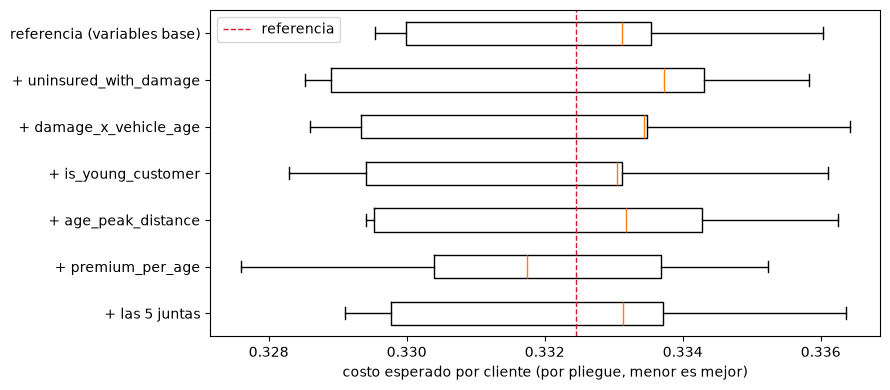

In [7]:
import matplotlib.pyplot as plt

order = list(features_table.index)
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([per_fold.loc[per_fold["model"] == n, "cost"] for n in order], vert=False, tick_labels=order, widths=0.5)
ax.axvline(features_table.loc["referencia (variables base)", "costo"], color="crimson", ls="--", lw=1, label="referencia")
ax.invert_yaxis(); ax.set_xlabel("costo esperado por cliente (por pliegue, menor es mejor)"); ax.legend()
plt.tight_layout(); plt.show()

In [8]:
features_table.to_csv(Path.cwd().resolve().parent / "reports" / "04_features_tabla.csv")
print("guardado: reports/04_features_tabla.csv")

guardado: reports/04_features_tabla.csv


## 6. Decisiones

Una fila por idea, con su cifra (LightGBM fijo, 5 pliegues, costo esperado por cliente; menor es mejor).

| # | Idea | Costo (referencia 0,33245) | Mejora / ruido | Pliegues que gana | Δ PR-AUC | Decisión según la regla | Motivo |
|---|---|---|---|---|---|---|---|
| 1 | `uninsured_with_damage` | 0,33226 | 0,06 | 3 de 5 | +0,0003 | descartar | Mejora 19 veces menor que el ruido |
| 2 | `damage_x_vehicle_age` | 0,33226 | 0,06 | 3 de 5 | −0,0001 | descartar | Igual a la referencia |
| 3 | `is_young_customer` | 0,33200 | 0,14 | 3 de 5 | −0,0001 | descartar | Mejora 7 veces menor que el ruido |
| 4 | `age_peak_distance` | 0,33253 | −0,03 | 3 de 5 | +0,0002 | descartar | No mejora |
| 5 | `premium_per_age` | 0,33173 | 0,24 | 3 de 5 | −0,0007 | descartar | La que más baja el costo, pero 4 veces menos que el ruido; empeora PR-AUC |
| — | Las 5 juntas | 0,33242 | 0,01 | 3 de 5 | −0,0003 | descartar | Sin efecto |

**Lectura:** ninguna variable pasa la regla (mejora / ruido > 1). LightGBM ya construye solo estas combinaciones a partir de las
variables originales (por ejemplo, "sin seguro y con daño"), así que no le aportan información nueva. Tampoco lo empeoran: todas
quedan dentro del ruido.

**Decisión del grupo (2026-10-31):** aun así, **el torneo del notebook 05 usa las 5 variables nuevas** (`use_engineered=True`).
Motivo: los modelos simples del torneo (regresión logística y árbol de decisión) no descubren solos interacciones ni la forma de
campana de la edad, y podrían beneficiarse; para LightGBM el efecto medido es nulo. Si en el torneo tampoco ayudan a los modelos
simples, se pueden apagar en la etapa 06 sin costo.

## Entregable de esta etapa

- [x] Cada idea tiene su fila con **mejora / ruido** y una decisión escrita.
- [x] Todas las variantes se midieron con **los mismos pliegues**.
- [x] Ninguna variable usa información que no se conoce **al predecir**.
- [x] El código reutilizable está en `src/proyecto/features/` y el notebook solo lo llama.
- [x] `reports/04_features.md` completado.